# Assignment 5. Bootstrap

For one K-means partition and one quantitative feature:

1. Find a **95% confidence interval** for the mean over the full dataset using bootstrap.
2. Compare the feature means in **two clusters** using bootstrap.
3. Select the cluster whose mean is **closest to the overall mean**, and compare its mean with the overall mean using bootstrap.

Apply both methods from the lecture: **pivotal** (bootstrap mean ± 1.96 bootstrap standard deviations) and **non-pivotal** (percentile). Interpret the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
df = pd.read_csv('spotify_pop_1000.csv')
df


,track_name,artists,popularity,duration_ms,explicit,danceability,energy,loudness,valence,tempo,acousticness
0,Blinding Lights,The Weeknd,91,200040,False,0.514,0.730,-5.934,0.334,171.005,0.00146
1,Mann Mera,Gajendra Verma,74,200120,False,0.535,0.765,-7.862,0.373,191.827,0.05400
2,Summer High,AP Dhillon,83,177391,False,0.860,0.541,-6.510,0.952,114.984,0.16500
3,Under The Influence,Chris Brown,96,184613,True,0.733,0.690,-5.529,0.310,116.992,0.06350
4,Starboy,The Weeknd;Daft Punk,90,230453,True,0.679,0.587,-7.015,0.486,186.003,0.14100
...,...,...,...,...,...,...,...,...,...,...,...
995,Yathe Yathe,G. V. Prakash,64,344360,False,0.448,0.607,-4.606,0.484,139.509,0.79100
996,Annul Maelae,Harris Jayaraj;Sudha Ragunathan,64,322506,False,0.773,0.436,-10.972,0.533,115.917,0.67200
997,Tu Mile Dil Khile,Raj Barman,62,197716,False,0.639,0.368,-14.096,0.415,89.940,0.24500
998,Vaarayo Vaarayo,Harris Jayaraj;Unnikrishnan;Chinmayi;Mega,64,316680,False,0.718,0.361,-9.740,0.446,103.000,0.56500


In [2]:
selected_features = ['danceability', 'energy', 'valence', 'acousticness', 'tempo']

X = df[selected_features].copy()
X_zscore = StandardScaler().fit_transform(X)
energy = df['energy'].to_numpy()
n = len(energy)

best_inertia = np.inf

for seed in range(15):
    model = KMeans(n_clusters=4, init='random', n_init=1, random_state=seed, max_iter=300, algorithm='lloyd')
    model.fit(X_zscore)
    if model.inertia_ < best_inertia:
        best_inertia = model.inertia_
        best_model = model
        best_seed = seed

old_labels = best_model.labels_

order = df.groupby(old_labels)['energy'].mean().sort_values().index

labels = old_labels.copy()

for new_number, old_number in enumerate(order, start=1):
    labels[old_labels == old_number] = new_number

cluster_summary = pd.DataFrame({'cluster': labels, 'energy': energy})
cluster_summary = cluster_summary.groupby('cluster')['energy'].agg(['size', 'mean'])
global_mean = energy.mean()

print(f'Observations: {n}; best random_state: {best_seed}; inertia: {best_inertia:.3f}')
print(f'Overall mean energy: {global_mean:.4f}')
display(cluster_summary.rename(columns={'size': 'Size', 'mean': 'Mean energy'}).round(4))

Observations: 1000; best random_state: 3; inertia: 2496.421
Overall mean energy: 0.6064


,Size,Mean energy
cluster,,
1,253,0.3998
2,235,0.6522
3,241,0.6565
4,271,0.7150


**Partition and feature.** I use the **K=4 partition from HW3** (features danceability, energy, valence, acousticness and tempo, standardized; the best of 15 random starts is `random_state=3` with objective 2496.421, so it is the same partition as in HW3) and the feature **energy**. As in HW3, clusters are numbered by increasing mean energy, with sizes 253, 235, 241 and 271.

I chose energy because it is the feature by which the clusters are ordered; the mean energy is 0.3998, 0.6522, 0.6565 and 0.7150 in clusters 1–4 and 0.6064 for the whole dataset. Note that energy was also one of the clustering features, so differences between clusters are partly built in by the clustering itself. The tests below should be read with this in mind.

All bootstrap runs use 10,000 resamples of the 1000 observations (with replacement) and a fixed random seed. Both versions are used: **pivotal** (bootstrap mean ± 1.96 bootstrap standard deviations) and **non-pivotal** (2.5th and 97.5th percentiles of the bootstrap distribution).

## Confidence Interval for the Overall Mean

In [3]:
n_bootstrap = 10000
alpha = 0.05
rng = np.random.default_rng(42)
bootstrap_means = np.zeros(n_bootstrap)

for i in range(n_bootstrap):
    sample = rng.choice(energy, size=n, replace=True)
    bootstrap_means[i] = sample.mean()

ci_mean_ref = bootstrap_means.mean() + np.array([-1, 1]) * 1.96 * bootstrap_means.std(ddof=1)

ci_mean_percentile = np.percentile(bootstrap_means, [100 * alpha / 2, 100 * (1 - alpha / 2)])

print(f'Original mean: {global_mean:.4f}')
print('Pivotal (95% confidence level):', np.round(ci_mean_ref, 4))
print('Non-Pivotal (95% confidence level):', np.round(ci_mean_percentile, 4))


Original mean: 0.6064
Pivotal (95% confidence level): [0.5956 0.6173]
Non-Pivotal (95% confidence level): [0.5957 0.6171]


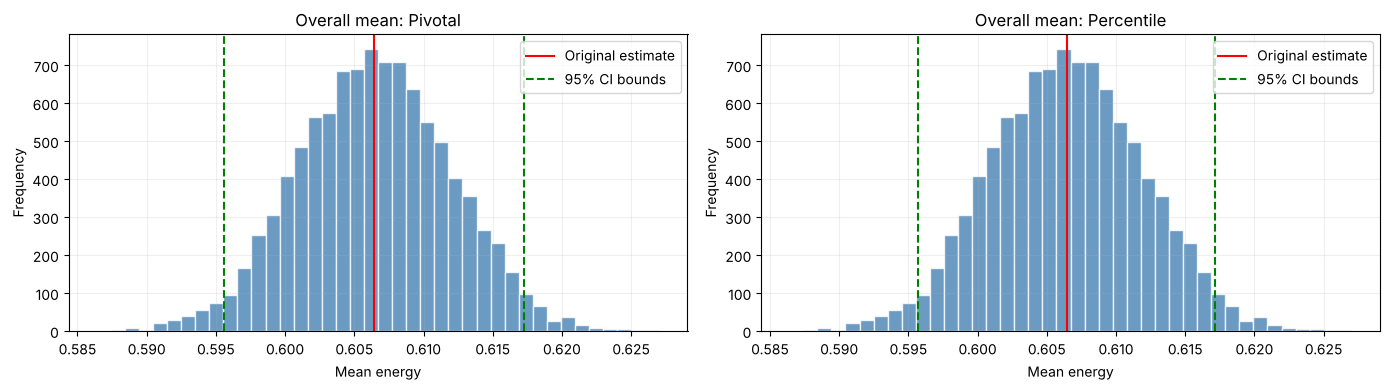

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, interval, method in zip(axes, [ci_mean_ref, ci_mean_percentile], ['Pivotal', 'Percentile']):
    ax.hist(bootstrap_means, bins=40, color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(global_mean, color='red', label='Original estimate')
    ax.axvline(interval[0], color='green', linestyle='--', label='95% CI bounds')
    ax.axvline(interval[1], color='green', linestyle='--')
    ax.set(title=f'Overall mean: {method}', xlabel='Mean energy', ylabel='Frequency')
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()


**Comment (task 1).** The 95% confidence interval for the grand mean of energy is **[0.5956, 0.6173]** by the pivotal method and **[0.5957, 0.6171]** by the non-pivotal (percentile) method. The two intervals are practically identical, because the bootstrap distribution of a mean of 1000 observations is almost symmetric and close to normal (see the histograms). The sample mean 0.6064 lies in the middle of the interval, and the interval is narrow (width about 0.022): the mean energy of pop tracks like these is estimated with a precision of about ±0.011.

Note that repeat listings of the same song are treated as independent observations here, so the true uncertainty is slightly larger.

## Comparing Two Clusters

In [5]:
cluster_3 = energy[labels == 3]
cluster_2 = energy[labels == 2]
diff_clusters = cluster_3.mean() - cluster_2.mean()

bootstrap_diffs = np.zeros(n_bootstrap)
rng = np.random.default_rng(42)

for i in range(n_bootstrap):
    indices = rng.choice(n, size=n, replace=True)
    sample = energy[indices]
    sample_labels = labels[indices] # Selected the labels of these observations.
    
    sample_3 = sample[sample_labels == 3] # Selected cluster 3 within the resample.
    sample_2 = sample[sample_labels == 2]

    bootstrap_diffs[i] = sample_3.mean() - sample_2.mean()

ci_diff_ref = bootstrap_diffs.mean() + np.array([-1, 1]) * 1.96 * bootstrap_diffs.std(ddof=1)
ci_diff_percentile = np.percentile(bootstrap_diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])

print(f'Cluster 3: n = {len(cluster_3)}, mean = {cluster_3.mean():.4f}')
print(f'Cluster 2: n = {len(cluster_2)}, mean = {cluster_2.mean():.4f}')
print(f'Mean difference: {diff_clusters:.4f}')
print('Pivotal:', np.round(ci_diff_ref, 4))
print('Non-Pivotal:', np.round(ci_diff_percentile, 4))

Cluster 3: n = 241, mean = 0.6565
Cluster 2: n = 235, mean = 0.6522
Mean difference: 0.0043
Pivotal: [-0.0176  0.0263]
Non-Pivotal: [-0.0179  0.026 ]


The hypothesis that within-cluster means of energy in clusters 2 and 3 are equal to each other **cannot be rejected** (it is accepted) at the 95% confidence level: both intervals, pivotal **[−0.0176, 0.0263]** and non-pivotal **[−0.0179, 0.0260]**, contain 0. The observed difference between the means (0.6565 − 0.6522 = 0.0043) is five times smaller than the half-width of the intervals (about 0.022), so it cannot be distinguished from random variation.

This agrees with the HW3 interpretation, where both clusters had an energy about 8% above the average (+7.6% and +8.3%): the clusters are separated by other features (cluster 2 has a slow tempo and low valence, cluster 3 is fast and cheerful), not by energy. Failing to reject equality does not prove that the means are exactly equal; it only shows that the data are consistent with equality.

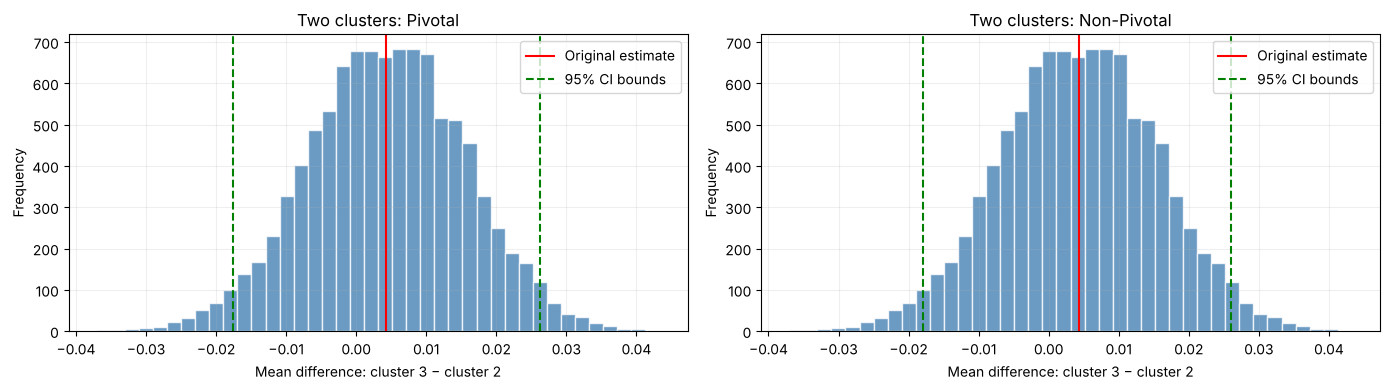

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, interval, method in zip(axes, [ci_diff_ref, ci_diff_percentile], ['Pivotal', 'Non-Pivotal']):
    ax.hist(bootstrap_diffs, bins=40, color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(diff_clusters, color='red', label='Original estimate')
    ax.axvline(interval[0], color='green', linestyle='--', label='95% CI bounds')
    ax.axvline(interval[1], color='green', linestyle='--')
    ax.set(title=f'Two clusters: {method}', xlabel='Mean difference: cluster 3 − cluster 2', ylabel='Frequency')
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()

## Comparing the Nearest Cluster with the Overall Mean

In [7]:
print(f'Overall mean energy: {global_mean:.4f}')
display(cluster_summary.rename(columns={'size': 'Size', 'mean': 'Mean energy'}).round(4))

Overall mean energy: 0.6064


,Size,Mean energy
cluster,,
1,253,0.3998
2,235,0.6522
3,241,0.6565
4,271,0.7150


In [8]:
distances = (cluster_summary['mean'] - global_mean).abs()
closest_cluster = distances.idxmin()
closest_mean = cluster_summary.loc[closest_cluster, 'mean']
diff_global = closest_mean - global_mean
display(cluster_summary.assign(distance=distances).round(4))
print(f'Closest cluster: {closest_cluster}')
print(f'Original difference: {diff_global:.4f}')


,size,mean,distance
cluster,,,
1,253,0.3998,0.2066
2,235,0.6522,0.0458
3,241,0.6565,0.0501
4,271,0.7150,0.1086


Closest cluster: 2
Original difference: 0.0458


In [9]:
bootstrap_global_diffs = np.zeros(n_bootstrap)
rng = np.random.default_rng(42)

for i in range(n_bootstrap):
    indices = rng.choice(n, size=n, replace=True)
    sample = energy[indices]
    mask = labels[indices] == closest_cluster
    bootstrap_global_diffs[i] = sample[mask].mean() - sample.mean()

ci_global_ref = bootstrap_global_diffs.mean() + np.array([-1, 1]) * 1.96 * bootstrap_global_diffs.std(ddof=1)
ci_global_percentile = np.percentile(bootstrap_global_diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])

print('Pivotal:', np.round(ci_global_ref, 4))
print('Non-Pivotal:', np.round(ci_global_percentile, 4))


Pivotal: [0.0297 0.062 ]
Non-Pivotal: [0.0298 0.0617]


The closest cluster to the grand mean is **cluster 2** (mean 0.6522, difference **+0.0458**); cluster 3 is almost as close (+0.0501), so this choice is a close call.

The hypothesis that the within-cluster-2 mean coincides with the grand mean is **rejected** at the 95% confidence level: both intervals, pivotal **[0.0297, 0.0620]** and non-pivotal **[0.0298, 0.0617]**, lie entirely above 0. Even the cluster nearest to the grand mean has a mean energy about 7.6% higher than the overall mean, which is larger than the random variation of the bootstrap. This is different from the insurance example in the reference, where the nearest cluster was consistent with the grand mean.

Both versions of the bootstrap give the same conclusions in all three tasks. Two cautions: the clusters were built from the same data (and energy was one of the clustering features), so such tests tend to find differences more easily than for groups defined in advance; and a cluster is part of the whole sample, so its mean and the grand mean are not independent.

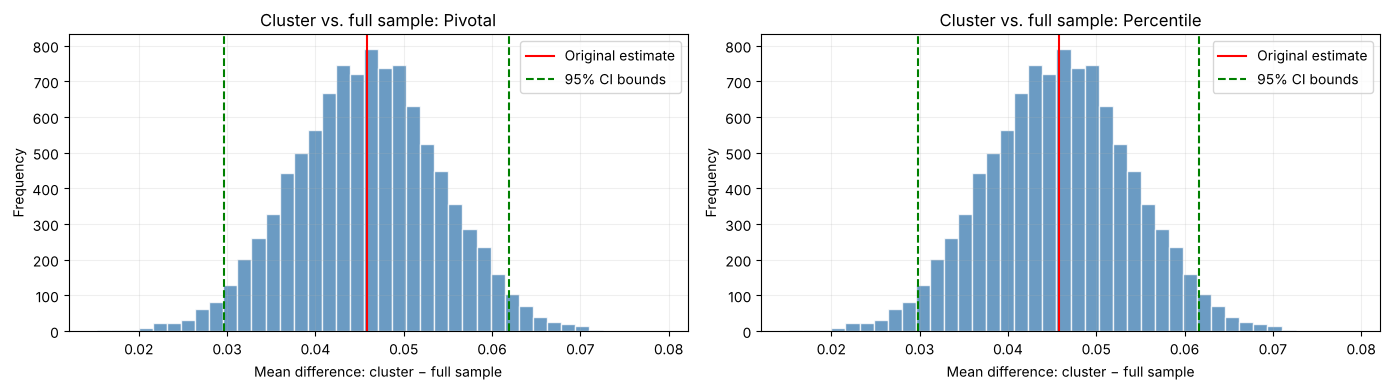

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, interval, method in zip(axes, [ci_global_ref, ci_global_percentile], ['Pivotal', 'Percentile']):
    ax.hist(bootstrap_global_diffs, bins=40, color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(diff_global, color='red', label='Original estimate')
    ax.axvline(interval[0], color='green', linestyle='--', label='95% CI bounds')
    ax.axvline(interval[1], color='green', linestyle='--')
    ax.set(title=f'Cluster vs. full sample: {method}', xlabel='Mean difference: cluster − full sample', ylabel='Frequency')
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()